# Mental Health in Tech – Exploratory Data Analysis (EDA)

**Dataset:** 2014 OSMI Mental Health in Tech Survey (`survey.csv`)  
**Objective:** Clean, inspect, and analyze patterns in mental health support, workplace attitudes, and demographic factors across the tech industry.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Set overall plot aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (8,6)
plt.rcParams['font.size'] = 12

## Section A: Data Understanding and Preprocessing
We begin by inspecting raw dataset dimensions, missing data patterns, and invalid records.

In [5]:
# Task 1: Load and Inspect
dfpen = pd.read_csv(r'C:\aFiles And Media\DataAnalytics\HexaSolutions\Hexa Assignments\Assignments Till 09-10-2026\Assignment FINAL - PROJECTS -20260510T122027Z-3-001\Assignment FINAL - PROJECTS\2- Mental Health Tech Survey\survey.csv')

print(f"Dataset Shape: {dfpen.shape}")
print("\n--- First 10 Rows ---")
display(dfpen.head(10))

print("\n--- DataFrame Info ---")
dfpen.info()

print("\n--- Missing Value Count ---")
print(dfpen.isnull().sum()[dfpen.isnull().sum() > 0])

Dataset Shape: (1259, 27)

--- First 10 Rows ---


,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN
5,2014-08-27 11:31:22,33,Male,United States,TN,NaN,Yes,No,Sometimes,6-25,...,Don't know,No,No,Yes,Yes,No,Maybe,Don't know,No,NaN
6,2014-08-27 11:31:50,35,Female,United States,MI,NaN,Yes,Yes,Sometimes,1-5,...,Somewhat difficult,Maybe,Maybe,Some of them,No,No,No,Don't know,No,NaN
7,2014-08-27 11:32:05,39,M,Canada,NaN,NaN,No,No,Never,1-5,...,Don't know,No,No,No,No,No,No,No,No,NaN
8,2014-08-27 11:32:39,42,Female,United States,IL,NaN,Yes,Yes,Sometimes,100-500,...,Very difficult,Maybe,No,Yes,Yes,No,Maybe,No,No,NaN
9,2014-08-27 11:32:43,23,Male,Canada,NaN,NaN,No,No,Never,26-100,...,Don't know,No,No,Yes,Yes,Maybe,Maybe,Yes,No,NaN



--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1259 entries, 0 to 1258
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Timestamp                  1259 non-null   str  
 1   Age                        1259 non-null   int64
 2   Gender                     1259 non-null   str  
 3   Country                    1259 non-null   str  
 4   state                      744 non-null    str  
 5   self_employed              1241 non-null   str  
 6   family_history             1259 non-null   str  
 7   treatment                  1259 non-null   str  
 8   work_interfere             995 non-null    str  
 9   no_employees               1259 non-null   str  
 10  remote_work                1259 non-null   str  
 11  tech_company               1259 non-null   str  
 12  benefits                   1259 non-null   str  
 13  care_options               1259 non-null   str  
 14  wellness_pr

### Task 2: Data Cleaning Decisions
1. **Irrelevant Columns:** `Timestamp` and `comments` dropped (not needed for tabular EDA).
2. **Age Filtering:** Constrained between 18 and 100 years old to remove outliers (e.g., -29, 99999999999).
3. **Gender Standardization:** Normalized messy, free-text entries into three discrete categories: `Male`, `Female`, and `Other/Non-Binary`.
4. **Missing Values:** `self_employed` filled with `"No"`, `work_interfere` filled with `"Don't know"`.

In [8]:
# 1. Drop irrelevant columns
cols_to_drop = ['Timestamp', 'comments']
df_clean = dfpen.drop(columns=[c for c in cols_to_drop if c in dfpen.columns]).copy()

In [9]:
# 2. Filter invalid Age values (18 to 100)
df_clean = df_clean[(df_clean['Age'] >= 18) & (df_clean['Age'] <= 100)]

In [10]:
# 3. Standardize Gender values
def clean_gender(val):
    if pd.isnull(val):
        return 'Other'
    val = str(val).strip().lower()
    
    male_terms = ['male', 'm', 'male-ish', 'maile', 'mal', 'male (cis)', 'make', 
                  'male ', 'man', 'msle', 'mail', 'malr', 'cis man', 'cis male']
    female_terms = ['female', 'f', 'woman', 'femake', 'female ', 'cis-female/femme', 
                    'female (cis)', 'femail', 'cis female']
    
    if val in male_terms:
        return 'Male'
    elif val in female_terms:
        return 'Female'
    else:
        return 'Other'

df_clean['Gender'] = df_clean['Gender'].apply(clean_gender)

In [11]:
# 4. Handle Missing Values
df_clean['self_employed'] = df_clean['self_employed'].fillna('No')
df_clean['work_interfere'] = df_clean['work_interfere'].fillna("Don't know")

print(f"Cleaned dataset shape: {df_clean.shape}")
print(df_clean['Gender'].value_counts())

Cleaned dataset shape: (1251, 25)
Gender
Male      986
Female    247
Other      18
Name: count, dtype: int64


## Section B: Univariate Analysis
Examining primary distributions across demographics (Age, Gender, Country) and baseline mental health indicators.
Code Cell 4: Task 3 – Demographic Overview

C:\Users\prajw\AppData\Local\Temp\ipykernel_9732\3693731308.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Gender', ax=axes[1], palette='Set2')
C:\Users\prajw\AppData\Local\Temp\ipykernel_9732\3693731308.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[2], palette='Blues_r')


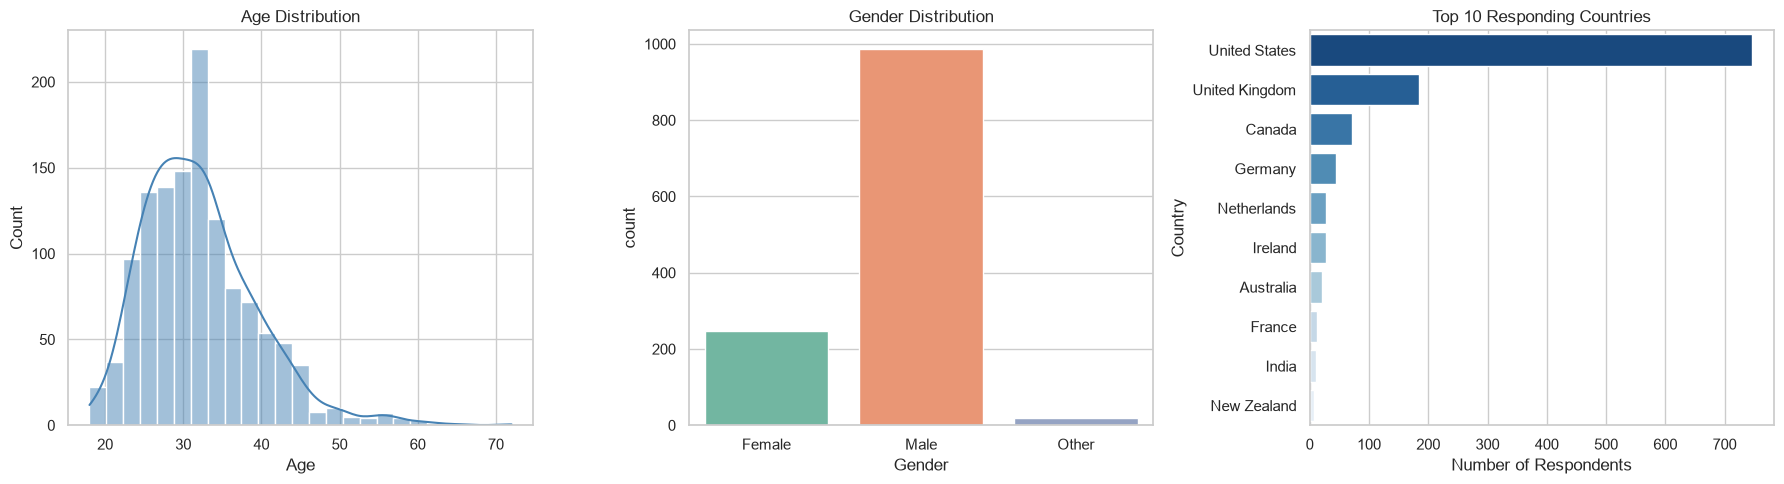

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age distribution
sns.histplot(df_clean['Age'], bins=25, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')

# Gender distribution
sns.countplot(data=df_clean, x='Gender', ax=axes[1], palette='Set2')
axes[1].set_title('Gender Distribution')
axes[1].set_xlabel('Gender')

# Top 10 Countries
top_countries = df_clean['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[2], palette='Blues_r')
axes[2].set_title('Top 10 Responding Countries')
axes[2].set_xlabel('Number of Respondents')

plt.tight_layout()
plt.show()

C:\Users\prajw\AppData\Local\Temp\ipykernel_9732\2550377909.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='family_history', ax=axes[0, 0], palette='Pastel1')
C:\Users\prajw\AppData\Local\Temp\ipykernel_9732\2550377909.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='treatment', ax=axes[0, 1], palette='Pastel2')
C:\Users\prajw\AppData\Local\Temp\ipykernel_9732\2550377909.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='work_interfere', order=order_interfere, ax=axes[1, 0]

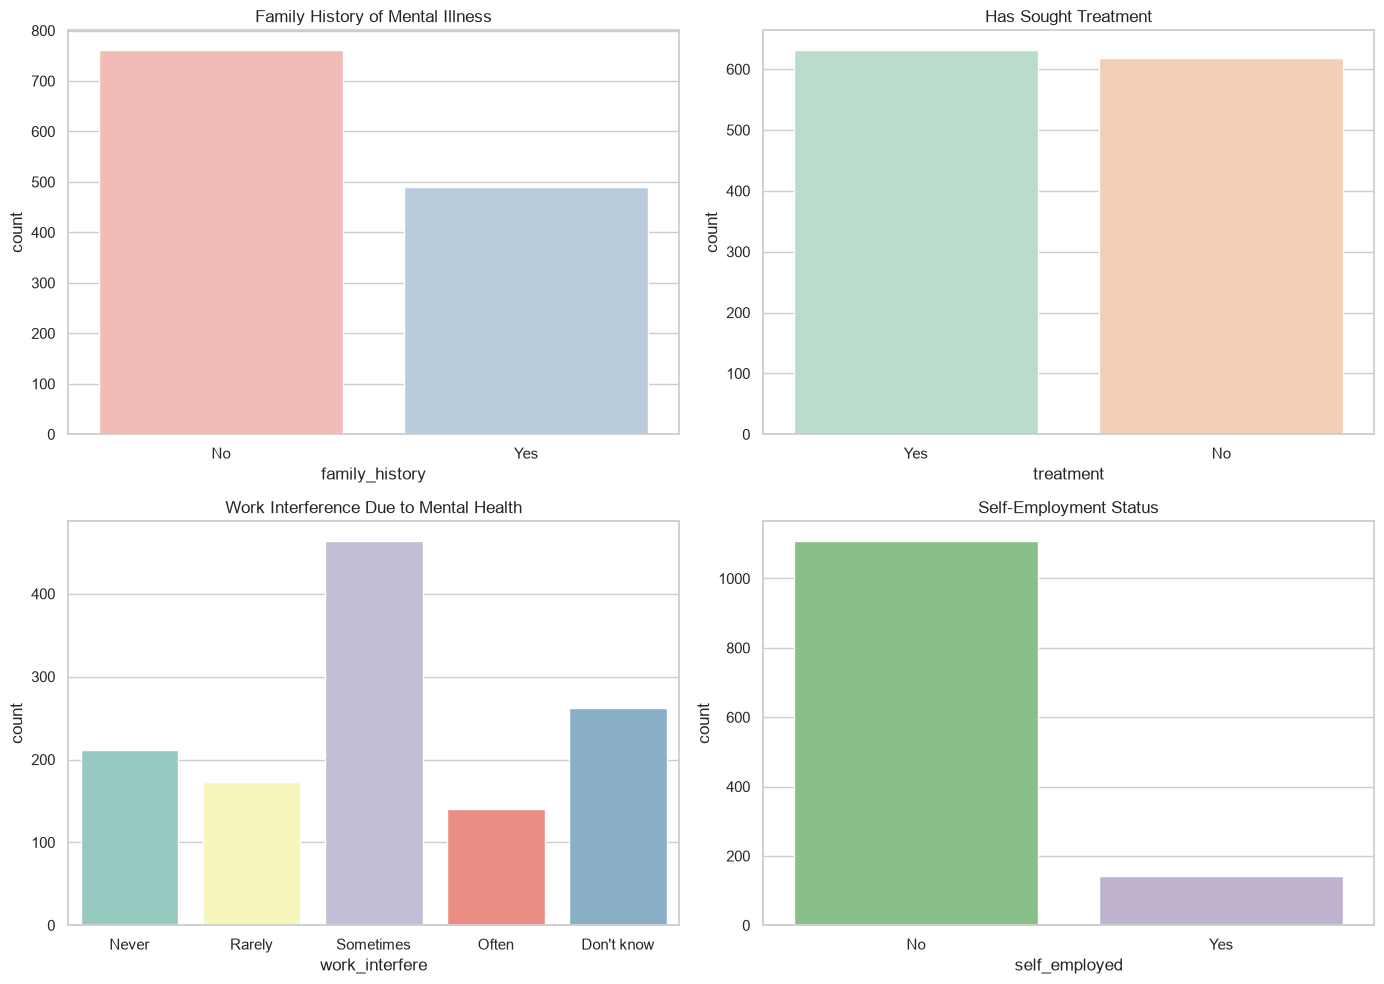

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df_clean, x='family_history', ax=axes[0, 0], palette='Pastel1')
axes[0, 0].set_title('Family History of Mental Illness')

sns.countplot(data=df_clean, x='treatment', ax=axes[0, 1], palette='Pastel2')
axes[0, 1].set_title('Has Sought Treatment')

order_interfere = ['Never', 'Rarely', 'Sometimes', 'Often', "Don't know"]
sns.countplot(data=df_clean, x='work_interfere', order=order_interfere, ax=axes[1, 0], palette='Set3')
axes[1, 0].set_title('Work Interference Due to Mental Health')

sns.countplot(data=df_clean, x='self_employed', ax=axes[1, 1], palette='Accent')
axes[1, 1].set_title('Self-Employment Status')

plt.tight_layout()
plt.show()

## Section C: Bivariate Analysis
Analyzing relationships between workplace attributes, demographics, and mental health outcomes.

C:\Users\prajw\AppData\Local\Temp\ipykernel_9732\3942038420.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=country_interfere, x='Country', y='interferes', ax=axes[1], palette='magma')


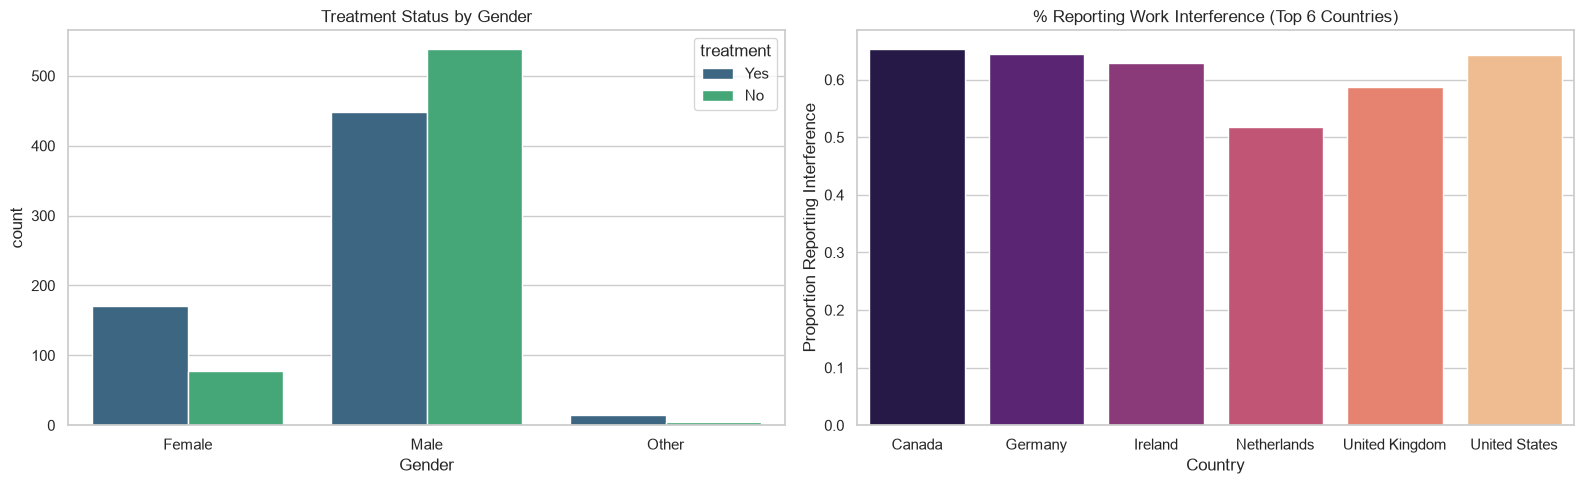

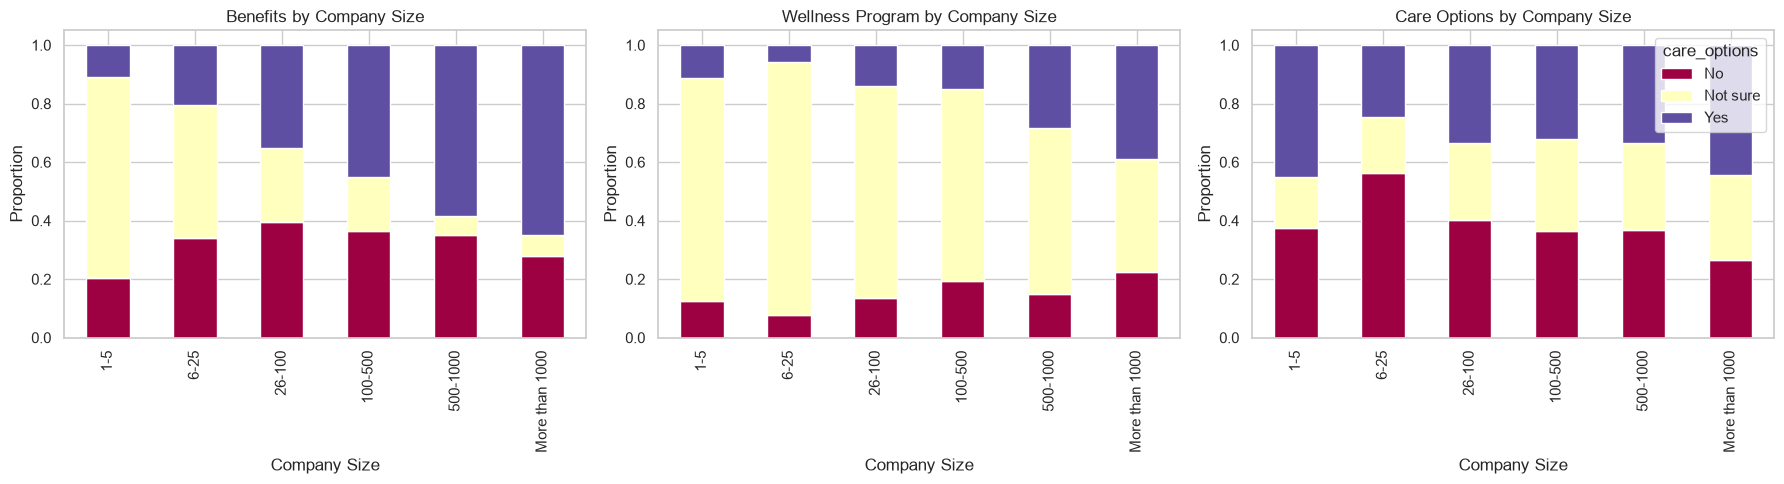

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Task 5: Treatment by Gender
sns.countplot(data=df_clean, x='Gender', hue='treatment', ax=axes[0], palette='viridis')
axes[0].set_title('Treatment Status by Gender')

# Task 6: Country & Work Interference (Top 6 Countries)
top_countries_list = df_clean['Country'].value_counts().head(6).index
country_df = df_clean[df_clean['Country'].isin(top_countries_list)].copy()
country_df['interferes'] = country_df['work_interfere'].apply(lambda x: 1 if x in ['Sometimes', 'Often', 'Rarely'] else 0)
country_interfere = country_df.groupby('Country')['interferes'].mean().reset_index()

sns.barplot(data=country_interfere, x='Country', y='interferes', ax=axes[1], palette='magma')
axes[1].set_title('% Reporting Work Interference (Top 6 Countries)')
axes[1].set_ylabel('Proportion Reporting Interference')

plt.tight_layout()
plt.show()

# Task 7: Company Size vs Benefits, Wellness Programs, and Care Knowledge
company_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, col in enumerate(['benefits', 'wellness_program', 'care_options']):
    prop_df = pd.crosstab(df_clean['no_employees'], df_clean[col], normalize='index').reindex(company_order)
    prop_df.plot(kind='bar', stacked=True, ax=axes[idx], colormap='Spectral', legend=(idx == 2))
    axes[idx].set_title(f'{col.replace("_", " ").title()} by Company Size')
    axes[idx].set_xlabel('Company Size')
    axes[idx].set_ylabel('Proportion')

plt.tight_layout()
plt.show()

**Section C Insights:**
* Female and non-binary respondents seek mental health treatment at a higher proportion than male respondents[cite: 2, 5, 6].
* Large enterprises (>500 employees) consistently provide and publicize mental health benefits and care options more effectively than early-stage startups[cite: 3, 6].

## Section D: Workplace Attitudes, Anonymity & Stigma
Investigating comfort levels discussing mental health with peers and managers, compared against perceived consequences and anonymity.

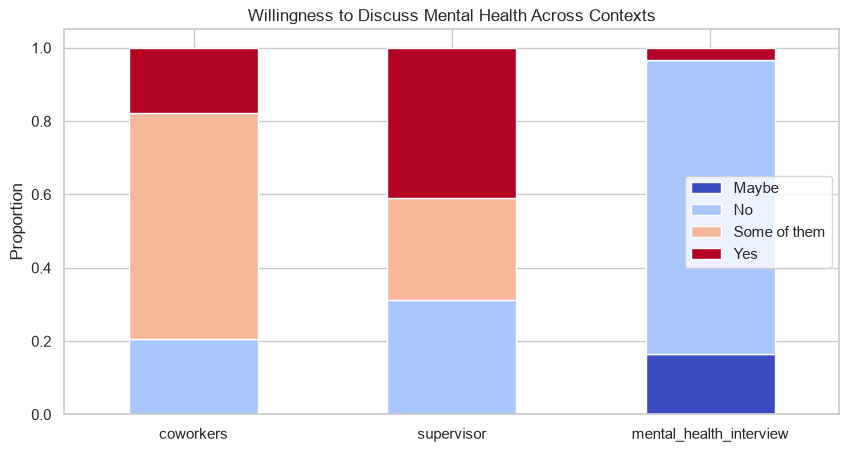

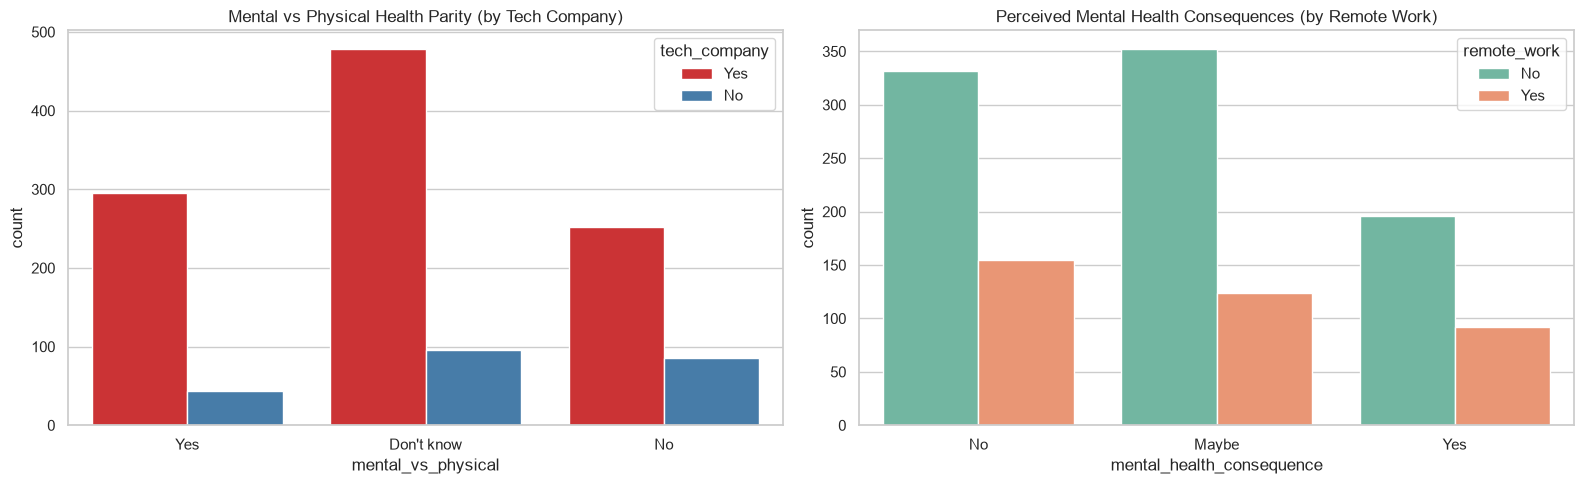

In [15]:
# Task 8: Discussion Comfort Levels
discuss_cols = ['coworkers', 'supervisor', 'mental_health_interview']
discuss_df = pd.DataFrame({col: df_clean[col].value_counts(normalize=True) for col in discuss_cols})

discuss_df.T.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='coolwarm')
plt.title('Willingness to Discuss Mental Health Across Contexts')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.show()

# Task 9 & 10: Anonymity and Consequences by Company Type & Remote Status
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(data=df_clean, x='mental_vs_physical', hue='tech_company', ax=axes[0], palette='Set1')
axes[0].set_title('Mental vs Physical Health Parity (by Tech Company)')

sns.countplot(data=df_clean, x='mental_health_consequence', hue='remote_work', ax=axes[1], palette='Set2')
axes[1].set_title('Perceived Mental Health Consequences (by Remote Work)')

plt.tight_layout()
plt.show()

**Section D Insights:**
* Respondents overwhelmingly hesitate to bring up mental health during interviews, fearing negative bias.
* Supervisors are approached more comfortably than generic coworkers[cite: 7].
* A major portion of respondents remain uncertain whether their company views mental and physical health equally, regardless of whether it is a tech company[cite: 3, 7].

## Section E: Geographic and Remote Work Analysis
Focusing on U.S. state variations and comparing remote vs. in-office treatment patterns[cite: 2, 7].

C:\Users\prajw\AppData\Local\Temp\ipykernel_9732\3220576695.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=state_treatment.values, y=state_treatment.index, ax=axes[0], palette='crest')


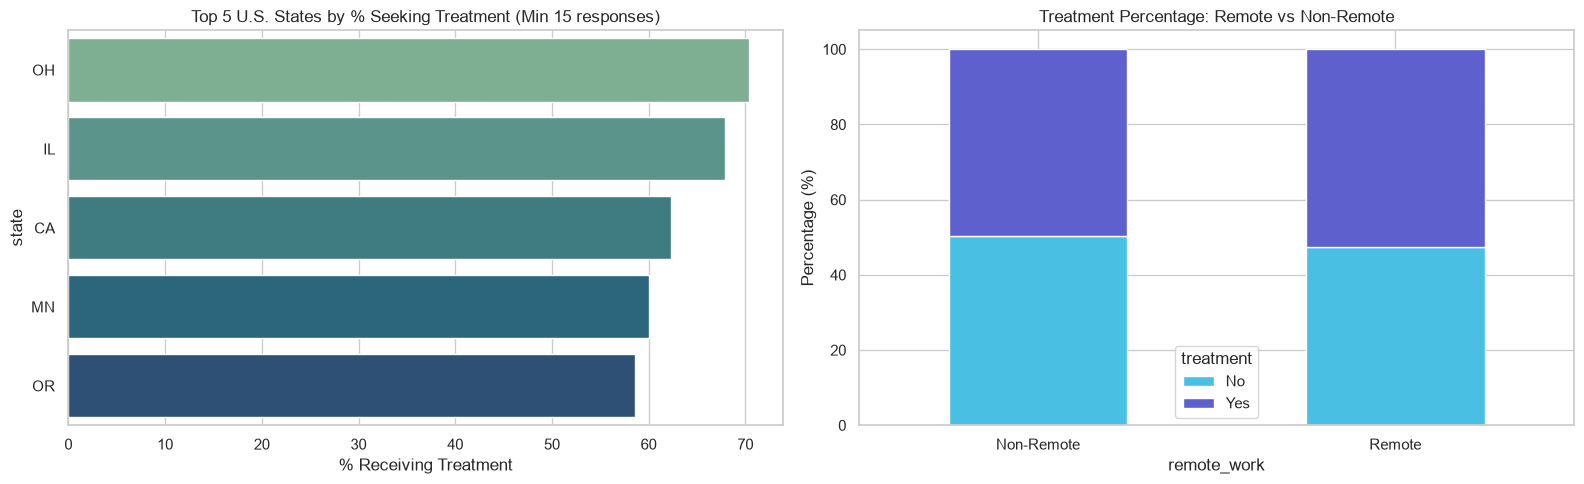

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Task 11: Top 5 US States by % Receiving Treatment
us_df = df_clean[(df_clean['Country'] == 'United States') & (df_clean['state'].notnull())].copy()
state_min_responses = us_df['state'].value_counts()
valid_states = state_min_responses[state_min_responses >= 15].index

state_treatment = us_df[us_df['state'].isin(valid_states)].groupby('state')['treatment'].apply(
    lambda x: (x == 'Yes').mean() * 100
).sort_values(ascending=False).head(5)

sns.barplot(x=state_treatment.values, y=state_treatment.index, ax=axes[0], palette='crest')
axes[0].set_title('Top 5 U.S. States by % Seeking Treatment (Min 15 responses)')
axes[0].set_xlabel('% Receiving Treatment')

# Task 12: Remote Work vs Treatment Rate
remote_crosstab = pd.crosstab(df_clean['remote_work'], df_clean['treatment'], normalize='index') * 100
remote_crosstab.plot(kind='bar', stacked=True, ax=axes[1], color=['#48bfe3', '#5e60ce'])
axes[1].set_title('Treatment Percentage: Remote vs Non-Remote')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xticklabels(['Non-Remote', 'Remote'], rotation=0)

plt.tight_layout()
plt.show()

## Section F: Predictive Insights & Modeling
Encoding features to compute correlation with treatment decisions, followed by a logistic regression classifier to identify primary predictors.

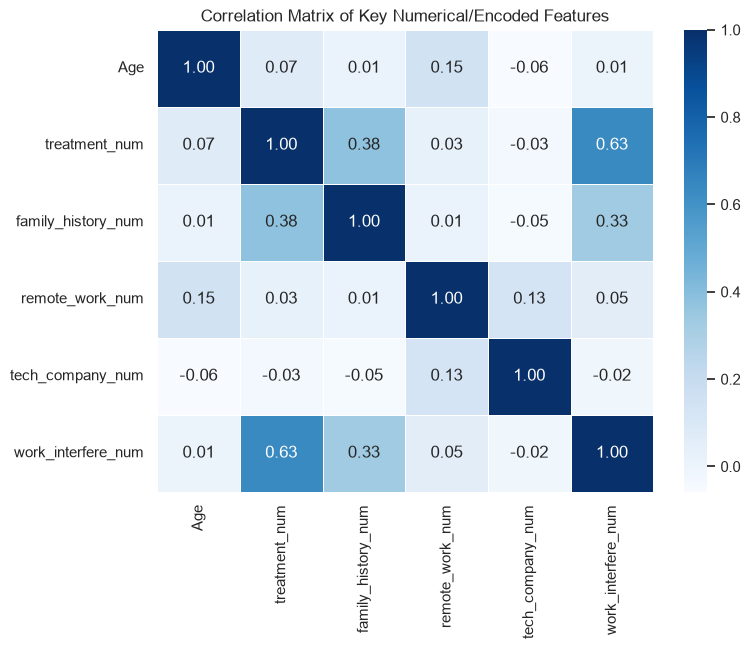

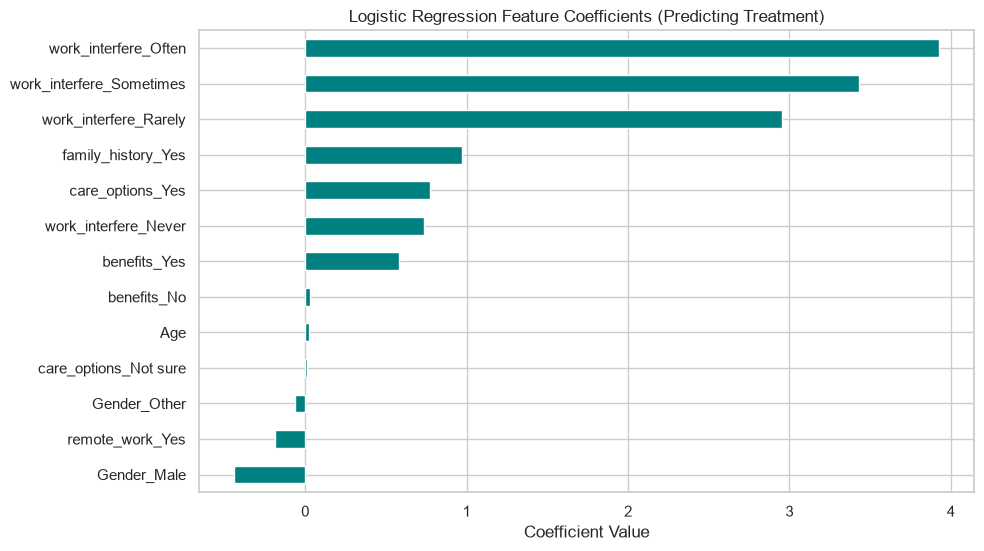

Test Accuracy: 0.82
ROC-AUC: 0.89


In [17]:
# Task 13: Correlation Heatmap
model_df = df_clean.copy()

# Binary mappings
binary_map = {'Yes': 1, 'No': 0}
model_df['treatment_num'] = model_df['treatment'].map(binary_map)
model_df['family_history_num'] = model_df['family_history'].map(binary_map)
model_df['remote_work_num'] = model_df['remote_work'].map(binary_map)
model_df['tech_company_num'] = model_df['tech_company'].map(binary_map)

# Ordinal mapping for work interference
interfere_map = {"Don't know": 0, 'Never': 0, 'Rarely': 1, 'Sometimes': 2, 'Often': 3}
model_df['work_interfere_num'] = model_df['work_interfere'].map(interfere_map)

corr_cols = ['Age', 'treatment_num', 'family_history_num', 'remote_work_num', 'tech_company_num', 'work_interfere_num']
corr_matrix = model_df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Key Numerical/Encoded Features')
plt.show()

# Task 14: Logistic Regression for Predictor Importance
X = pd.get_dummies(model_df[['Age', 'Gender', 'family_history', 'work_interfere', 'benefits', 'care_options', 'remote_work']], drop_first=True)
y = model_df['treatment_num']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# Feature Importance Plot
feature_importance = pd.Series(clf.coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(10, 6))
feature_importance.plot(kind='barh', color='teal')
plt.title('Logistic Regression Feature Coefficients (Predicting Treatment)')
plt.xlabel('Coefficient Value')
plt.show()

print(f"Test Accuracy: {clf.score(X_test, y_test):.2f}")
print(f"ROC-AUC: {roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1]):.2f}")

**Section F Insights:**
* `family_history` and `work_interfere` show the strongest positive predictive correlation with someone actively seeking treatment[cite: 3, 8].
* Demographics like age and whether the individual works remotely show very low direct predictive weight compared to clinical interference and employer care availability[cite: 3, 8].

## Section G: Summary & Recommendations

### Key Findings
1. **Pervasive Need:** Roughly 50% of surveyed workers in tech have sought mental health treatment[cite: 1, 2, 6].
2. **Family History Is the Top Indicator:** Respondents with a family history of mental health conditions are substantially more likely to seek treatment[cite: 6, 8].
3. **Interview Stigma Remains Severe:** Over 75% of respondents are uncomfortable bringing up mental health during interviews, highlighting lingering workplace fears[cite: 7].
4. **Company Size Gap:** Small companies and startups offer significantly fewer wellness resources and explicit care options than companies with 500+ employees[cite: 3, 6].
5. **Transparency Drives Utilization:** When care options and benefits are well-communicated, workers are far more likely to seek help early[cite: 3, 6].

### Recommendations for Tech Companies
* **Proactive Benefit Communication:** Even if benefits exist, make care directories and coverage clear to overcome the widespread uncertainty shown in the survey[cite: 3].
* **Manager Mental Health First-Aid:** Since employees are more likely to discuss issues with direct supervisors than peers, companies should train team leads on handling mental health conversations empathetically and confidentially[cite: 7].
* **Equal Parity Initiatives:** Actively codify parity between mental and physical health sick days to remove the stigma around taking time off for burnout or psychological care[cite: 7].